# Mumbai PM2.5 forecasting – final pipeline

Forecasts hourly PM2.5 at the 4 target stations for the private window (**11–12 Nov 2026**).

**Inputs**
* `Train.csv` (CPCB / OpenAQ observations, provided by the organisers)
* Open-Meteo weather: archived forecasts for training, live forecast for the target days (listed on ClimateVerse)
* CAMS PM2.5 forecast via the Open-Meteo Air-Quality API (set `USE_CAMS = False` to run without it)

**Model** – LightGBM ensemble trained on rolling forecast origins (every 12 h, horizons 1–96 h), using
recent-level features, diurnal profile, weather at the target hour, and the station-bias-corrected CAMS forecast.
Log-target and CAMS-residual models are averaged; recent data weighted with a 180-day half-life.

**Diwali** – firework spikes on the night of 8→9 Nov are hidden from the "recent level" features so they
don't inflate the 11–12 Nov forecast.

In [1]:
# ---------------- configuration ----------------
USE_CAMS       = True     # False -> only Train.csv + Open-Meteo weather
MASK_DIWALI    = True     # hide Diwali-night firework hours from recent-level features
DIWALI_MASK    = ('2026-11-08 12:00', '2026-11-09 12:00')
REFRESH_HOURS  = 3        # re-download weather/CAMS if the cached files are older than this
RUN_BACKTEST   = True     # rolling-origin validation at the 24-72 h horizon
SEEDS          = (0, 1, 2, 3, 4)
OUT            = 'submission_notebook.csv'

import os, time, sys, warnings
import pandas as pd, numpy as np, lightgbm as lgb, requests
warnings.filterwarnings('ignore'); os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')

'8'

## 1. External data (Open-Meteo weather + CAMS)

In [2]:
stale = (not os.path.exists('ext/aq.csv')) or (time.time() - os.path.getmtime('ext/aq.csv') > REFRESH_HOURS * 3600)
print('refreshing external data' if stale else 'using cached ext/ files (fresh enough)')
if stale:
    os.makedirs('ext', exist_ok=True)
    st = pd.read_csv('Stations.csv')
    W = 'temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,wind_speed_10m,wind_direction_10m,wind_gusts_10m,boundary_layer_height,surface_pressure,cloud_cover,shortwave_radiation'
    A = 'pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,aerosol_optical_depth'
    START, END = '2025-02-01', (pd.Timestamp.now() + pd.Timedelta(days=6)).strftime('%Y-%m-%d')

    def get(url, params):
        for k in range(5):
            r = requests.get(url, params=params, timeout=120)
            if r.ok: return r.json()
            print('retry', r.status_code, r.text[:200]); time.sleep(5 * (k + 1))
        r.raise_for_status()

    def frame(js, loc):
        d = pd.DataFrame(js['hourly']); d['time'] = pd.to_datetime(d['time']); d['location_id'] = loc; return d

    wx, aq = [], []
    today = pd.Timestamp.now().normalize()
    for _, s in st.iterrows():
        base = dict(latitude=s.latitude, longitude=s.longitude, timezone='Asia/Kolkata')
        # archived forecasts (consistent with what a live forecast looks like)
        h = frame(get('https://historical-forecast-api.open-meteo.com/v1/forecast',
                      {**base, 'hourly': W, 'start_date': START, 'end_date': (today - pd.Timedelta(days=1)).strftime('%Y-%m-%d')}), s.location_id)
        f = frame(get('https://api.open-meteo.com/v1/forecast',
                      {**base, 'hourly': W, 'past_days': 3, 'forecast_days': 7}), s.location_id)
        w = pd.concat([h, f]).drop_duplicates(['location_id', 'time'], keep='last'); wx.append(w)
        a = frame(get('https://air-quality-api.open-meteo.com/v1/air-quality',
                      {**base, 'hourly': A, 'start_date': START, 'end_date': END}), s.location_id)
        aq.append(a)
        print(s.location_id, len(w), w.time.min(), w.time.max(), '| aq', len(a), a.dropna(subset=['pm2_5']).time.max())
    pd.concat(wx).to_csv('ext/weather.csv', index=False)
    pd.concat(aq).to_csv('ext/aq.csv', index=False)

using cached ext/ files (fresh enough)


## 2. Feature pipeline

In [3]:

CAP = 500.0
WX = ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'wind_speed_10m', 'wind_gusts_10m',
      'boundary_layer_height', 'surface_pressure', 'cloud_cover', 'shortwave_radiation']
AQV = ['pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'dust', 'aerosol_optical_depth']
# Lakshmi Puja dates (Diwali main night)
DIWALI = pd.to_datetime(['2018-11-07', '2019-10-27', '2020-11-14', '2021-11-04', '2022-10-24', '2023-11-12',
                         '2024-11-01', '2025-10-21', '2026-11-08'])


def load_obs(path='Train.csv'):
    tr = pd.read_csv(path)
    tr['t'] = pd.to_datetime(tr.timestamp_ist).dt.tz_localize(None) - pd.Timedelta(hours=1)  # hour START
    tr.loc[tr.pm25 > CAP, 'pm25'] = np.nan
    P = tr.pivot_table(index='t', columns='location_id', values='pm25')
    P = P.reindex(pd.date_range(P.index.min().floor('D'), P.index.max(), freq='h'))
    return P


def load_ext():
    w = pd.read_csv('ext/weather.csv', parse_dates=['time'])
    a = pd.read_csv('ext/aq.csv', parse_dates=['time'])
    m = w.merge(a, on=['location_id', 'time'], how='outer').sort_values(['location_id', 'time'])
    rad = np.deg2rad(m.wind_direction_10m)
    m['u'] = -m.wind_speed_10m * np.sin(rad); m['v'] = -m.wind_speed_10m * np.cos(rad)
    out = []
    for loc, g in m.groupby('location_id'):
        g = g.set_index('time').asfreq('h'); g['location_id'] = loc
        g['rain24'] = g.precipitation.rolling(24, min_periods=1).sum()
        g['rain72'] = g.precipitation.rolling(72, min_periods=1).sum()
        g['ws12'] = g.wind_speed_10m.rolling(12, min_periods=1).mean()
        g['u24'] = g.u.rolling(24, min_periods=1).mean(); g['v24'] = g.v.rolling(24, min_periods=1).mean()
        g['blh6'] = g.boundary_layer_height.rolling(6, min_periods=1).mean()
        g['blh24'] = g.boundary_layer_height.rolling(24, min_periods=1, center=True).mean()
        g['cams24'] = g.pm2_5.rolling(24, min_periods=1, center=True).mean()
        g['cams6'] = g.pm2_5.rolling(6, min_periods=1, center=True).mean()
        out.append(g.reset_index())
    return pd.concat(out).rename(columns={'time': 't'})


def diwali_day(t):
    t = pd.DatetimeIndex(t).normalize()
    d = np.full(len(t), 99.0)
    for D in DIWALI:
        dd = (t - D).days.values.astype(float)
        d = np.where(np.abs(dd) < np.abs(d), dd, d)
    return np.clip(d, -15, 15)


def station_stats(P, C):
    """Per-station stats from obs with start < C."""
    h = P.loc[:C - pd.Timedelta(hours=1)].iloc[-24 * 28:]
    r = {}
    for l in P.columns:
        s = h[l]
        nn = s.dropna()
        r[l] = dict(last=nn.iloc[-1] if len(nn) else np.nan, age=(C - nn.index[-1]).total_seconds() / 3600 if len(nn) else 999,
                    l6=s.iloc[-6:].mean(), l24=s.iloc[-24:].mean(), l72=s.iloc[-72:].mean(), l168=s.iloc[-168:].mean(),
                    l336=s.iloc[-336:].mean(), l672=s.mean(),
                    prof=s.iloc[-336:].groupby(s.iloc[-336:].index.hour).mean(),
                    prof7=s.iloc[-168:].groupby(s.iloc[-168:].index.hour).mean(),
                    sd168=s.iloc[-168:].std())
    return r


def build(P, E, origins, gaps, need_y=True):
    Ei = E.set_index(['location_id', 't'])
    rows = []
    for C in origins:
        S = station_stats(P, C)
        a24 = np.nanmean([S[l]['l24'] for l in P.columns]); a168 = np.nanmean([S[l]['l168'] for l in P.columns])
        for l in P.columns:
            r = S[l]
            if np.isnan(r['l168']): continue
            for g in gaps:
                t = C + pd.Timedelta(hours=int(g))
                rows.append((l, C, t, g, r['last'], r['age'], r['l6'], r['l24'], r['l72'], r['l168'], r['l336'], r['l672'],
                             r['prof'].get(t.hour, np.nan), r['prof7'].get(t.hour, np.nan), r['sd168'], a24, a168))
    d = pd.DataFrame(rows, columns=['location_id', 'C', 't', 'gap', 'last', 'age', 'l6', 'l24', 'l72', 'l168', 'l336', 'l672',
                                    'prof', 'prof7', 'sd168', 'a24', 'a168'])
    # external features at target time
    d = d.join(Ei, on=['location_id', 't'])
    # external context at cutoff time (mean of 72h before C) -> anomalies
    ctx = E.copy()
    for c in ['pm2_5', 'boundary_layer_height', 'wind_speed_10m']:
        ctx[c + '_p72'] = ctx.groupby('location_id')[c].transform(lambda s: s.rolling(72, min_periods=12).mean())
    ctx = ctx.set_index(['location_id', 't'])[['pm2_5_p72', 'boundary_layer_height_p72', 'wind_speed_10m_p72']]
    d['Cm1'] = d.C - pd.Timedelta(hours=1)
    d = d.join(ctx, on=['location_id', 'Cm1'])
    # obs/CAMS bias over the last 7 days before C
    camsP = E.pivot_table(index='t', columns='location_id', values='pm2_5').reindex(P.index)
    ratio = {}
    for C in origins:
        o = P.loc[C - pd.Timedelta(hours=168):C - pd.Timedelta(hours=1)]; c = camsP.loc[o.index]
        for l in P.columns:
            m = o[l].notna() & c[l].notna()
            ratio[(l, C)] = o[l][m].mean() / max(c[l][m].mean(), 1) if m.sum() > 24 else np.nan
    d['bias7'] = [ratio[(l, C)] for l, C in zip(d.location_id, d.C)]
    d['cams_adj'] = d.pm2_5 * d.bias7
    d['cams24_adj'] = d.cams24 * d.bias7
    d['cams_anom'] = d.cams24 / d.pm2_5_p72
    d['blh_anom'] = d.blh24 / d.boundary_layer_height_p72
    d['ws_anom'] = d.ws12 - d.wind_speed_10m_p72
    d['hour'] = d.t.dt.hour; d['dow'] = d.t.dt.dayofweek; d['doy'] = d.t.dt.dayofyear
    d['dwl'] = diwali_day(d.t); d['dwlC'] = diwali_day(d.C)
    d['loc'] = pd.Categorical(d.location_id, categories=sorted(P.columns))
    if need_y:
        Pl = P.stack().rename('y').reset_index().rename(columns={'level_0': 't', 'level_1': 'location_id'})
        Pl.columns = ['t', 'location_id', 'y']
        d = d.merge(Pl, on=['t', 'location_id'], how='left')
    return d.drop(columns=['Cm1'])


FEATS = ['loc', 'gap', 'hour', 'dow', 'doy', 'last', 'age', 'l6', 'l24', 'l72', 'l168', 'l336', 'l672', 'prof', 'prof7', 'sd168',
         'a24', 'a168', 'dwl',
         'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'wind_speed_10m', 'wind_gusts_10m',
         'boundary_layer_height', 'surface_pressure', 'cloud_cover', 'shortwave_radiation', 'u', 'v', 'u24', 'v24',
         'rain24', 'rain72', 'ws12', 'blh6', 'blh24',
         'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'dust', 'aerosol_optical_depth', 'cams24', 'cams6',
         'bias7', 'cams_adj', 'cams24_adj', 'cams_anom', 'blh_anom', 'ws_anom']


## 3. Load observations

In [4]:
P = load_obs(); E = load_ext()
last_obs = P.dropna(how='all').index[-1]
C = last_obs + pd.Timedelta(hours=1)
P_true = P.copy()
if MASK_DIWALI:
    print('Diwali-night values being hidden:'); print(P.loc[DIWALI_MASK[0]:DIWALI_MASK[1]].dropna(how='all').round(0))
    P.loc[DIWALI_MASK[0]:DIWALI_MASK[1]] = np.nan
print('last observation (hour start):', last_obs, '-> forecast cutoff', C)
P_true.loc['2026-10-20':].resample('D').mean().round(1)

Diwali-night values being hidden:
location_id          11606    11611    3409510  3409511
2026-11-09 01:00:00     52.0      NaN    351.0      NaN
2026-11-09 02:00:00     45.0    325.0      NaN      NaN
2026-11-09 03:00:00     49.0    186.0      NaN    152.0
2026-11-09 04:00:00     38.0    115.0    111.0    108.0
2026-11-09 05:00:00     21.0     79.0      NaN     96.0
2026-11-09 06:00:00      NaN     65.0      NaN     90.0
last observation (hour start): 2026-11-09 06:00:00 -> forecast cutoff 2026-11-09 07:00:00


location_id,11606,11611,3409510,3409511
2026-10-20,63.4,66.3,47.7,59.8
2026-10-21,54.5,61.5,54.1,63.8
2026-10-22,53.2,56.8,49.0,58.1
2026-10-23,57.4,63.7,49.2,59.1
2026-10-24,NaN,NaN,NaN,NaN
2026-10-25,NaN,NaN,NaN,NaN
2026-10-26,NaN,NaN,NaN,NaN
2026-10-27,48.8,48.1,31.1,44.7
2026-10-28,40.7,35.8,25.5,46.9
2026-10-29,40.0,41.3,21.8,40.5


## 4. Training set + models

In [5]:
F = [f for f in FEATS if f not in ('doy', 'dwl')]
CAMSF = ('pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'dust', 'aerosol_optical_depth', 'cams24', 'cams6',
         'bias7', 'cams_adj', 'cams24_adj', 'cams_anom')
if not USE_CAMS: F = [f for f in F if f not in CAMSF]
P0 = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
          colsample_bytree=0.7, reg_lambda=5, verbose=-1)
P1 = dict(P0, num_leaves=15, min_child_samples=300, n_estimators=800, colsample_bytree=0.5)
CONFIGS = (('log', P0), ('log', P1), ('resc', P1)) if USE_CAMS else (('log', P0), ('log', P1))
HL = 180

origins = list(pd.date_range('2025-03-10', C, freq='12h'))
maxg = int((pd.Timestamp('2026-11-13') - C).total_seconds() // 3600)
GAPS = list(range(1, 97)) + (list(range(97, maxg + 1, 3)) if maxg > 96 else [])
d = build(P, E, origins, GAPS).dropna(subset=['y'])
d['base'] = d.l168.fillna(d.l336).fillna(d.l672); d['cb'] = d.cams24_adj.fillna(d.base)
print('training rows:', len(d), '| features:', len(F), '| max horizon needed:', maxg, 'h')

def fit(trn, seeds=SEEDS):
    w = 0.5 ** ((trn.t.max() - trn.t).dt.days / HL)
    ms = []
    for mode, prm in CONFIGS:
        yt = np.log1p(trn.y) if mode == 'log' else np.log1p(trn.y) - np.log1p(trn.cb)
        yt = np.ascontiguousarray(np.asarray(yt, dtype=np.float64)); ww = np.ascontiguousarray(np.asarray(w, dtype=np.float64))
        X = trn[F].copy()
        for s in seeds: ms.append((mode, lgb.LGBMRegressor(random_state=s, **prm).fit(X, yt, sample_weight=ww)))
    return ms

def predict(ms, f):
    ps = {'log': [], 'resc': []}
    for mode, m in ms:
        p = m.predict(f[F]); ps[mode].append(np.expm1(p) if mode == 'log' else np.expm1(p + np.log1p(f.cb)))
    p = (2 * np.mean(ps['log'], 0) + np.mean(ps['resc'], 0)) / 3 if ps['resc'] else np.mean(ps['log'], 0)
    return np.clip(p, 0, None)

training rows: 368720 | features: 50 | max horizon needed: 89 h


## 5. Backtest (rolling origin, targets 24–72 h after a midnight cutoff)

In [6]:
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
if RUN_BACKTEST:
    FOLDS = [('2025-11-20', '2026-01-15'), ('2026-02-01', '2026-04-01'), ('2026-04-01', '2026-06-01'),
             ('2026-09-01', '2026-10-01'), ('2026-10-01', '2026-11-03')]
    res = []
    for a, b in FOLDS:
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        ev = d[(d.C >= a) & (d.C < b) & (d.gap >= 24) & (d.gap <= 72) & (d.C.dt.hour == 0)]
        p = predict(fit(d[d.t < a], seeds=(0,)), ev)
        res.append({'fold': a.date(), 'n': len(ev), 'persistence_7d': rmse(ev.y, ev.base),
                    'cams_bias_corrected': rmse(ev.y, ev.cb), 'model': rmse(ev.y, p)})
    R = pd.DataFrame(res).set_index('fold'); R.loc['mean'] = R.mean(); display(R.round(2))

,n,persistence_7d,cams_bias_corrected,model
fold,,,,
2025-11-20,7849.0,30.94,30.25,29.97
2026-02-01,8611.0,22.35,17.58,15.62
2026-04-01,9920.0,17.65,15.93,15.79
2026-09-01,5341.0,10.55,10.02,8.07
2026-10-01,5104.0,15.68,13.05,11.11
mean,7365.0,19.43,17.36,16.11


## 6. Final models and forecast

In [7]:
models = fit(d)
te = pd.read_csv('Test.csv'); sm = pd.read_csv('SampleSubmission.csv')
te['t'] = pd.to_datetime(te.target_start_ist).dt.tz_localize(None)

def forecast(C0, ts):
    gaps = sorted({int((t - C0).total_seconds() // 3600) for t in ts})
    f = build(P, E, [C0], gaps, need_y=False)
    f['base'] = f.l168.fillna(f.l336).fillna(f.l672); f['cb'] = f.cams24_adj.fillna(f.base)
    f['p'] = predict(models, f); return f.set_index(['location_id', 't'])

pf = forecast(C, te[te.t >= C].t.unique())
te['p'] = [pf.p.get((l, t), np.nan) for l, t in zip(te.location_id, te.t)]
# rows before the cutoff: observation if known, otherwise a 1-day-ahead forecast
for i in te.index[te.t < C]:
    l, t = te.at[i, 'location_id'], te.at[i, 't']
    o = P_true.at[t, l] if t in P_true.index else np.nan
    if not np.isnan(o): te.at[i, 'p'] = o
miss = te[te.p.isna()].copy(); miss['c0'] = miss.t.dt.normalize() - pd.Timedelta(days=1)
for c0, g in miss.groupby('c0'):
    f = forecast(c0, g.t.unique())
    for i in g.index: te.at[i, 'p'] = f.p.get((te.at[i, 'location_id'], te.at[i, 't']), np.nan)
te['p'] = te.p.fillna(te.groupby('location_id').p.transform('median'))

sub = sm[['ID']].merge(te[['ID', 'p']], on='ID', how='left').rename(columns={'p': 'Target'})
assert list(sub.ID) == list(sm.ID) and len(sub) == 2592 and np.isfinite(sub.Target).all() and (sub.Target >= 0).all()
sub.to_csv(OUT, index=False); print('wrote', OUT)
pv = te[(te.t >= '2026-11-11') & (te.t < '2026-11-13')]
print('Private window 11-12 Nov – daily mean forecast by station:')
pv.groupby([pv.t.dt.date, 'location_id']).p.mean().unstack().round(1)

wrote submission_notebook.csv
Private window 11-12 Nov – daily mean forecast by station:


location_id,11606,11611,3409510,3409511
t,,,,
2026-11-11,43.4,41.6,32.4,46.2
2026-11-12,44.2,44.4,32.9,46.9


## 7. Plot: recent observations and the 11–12 Nov forecast

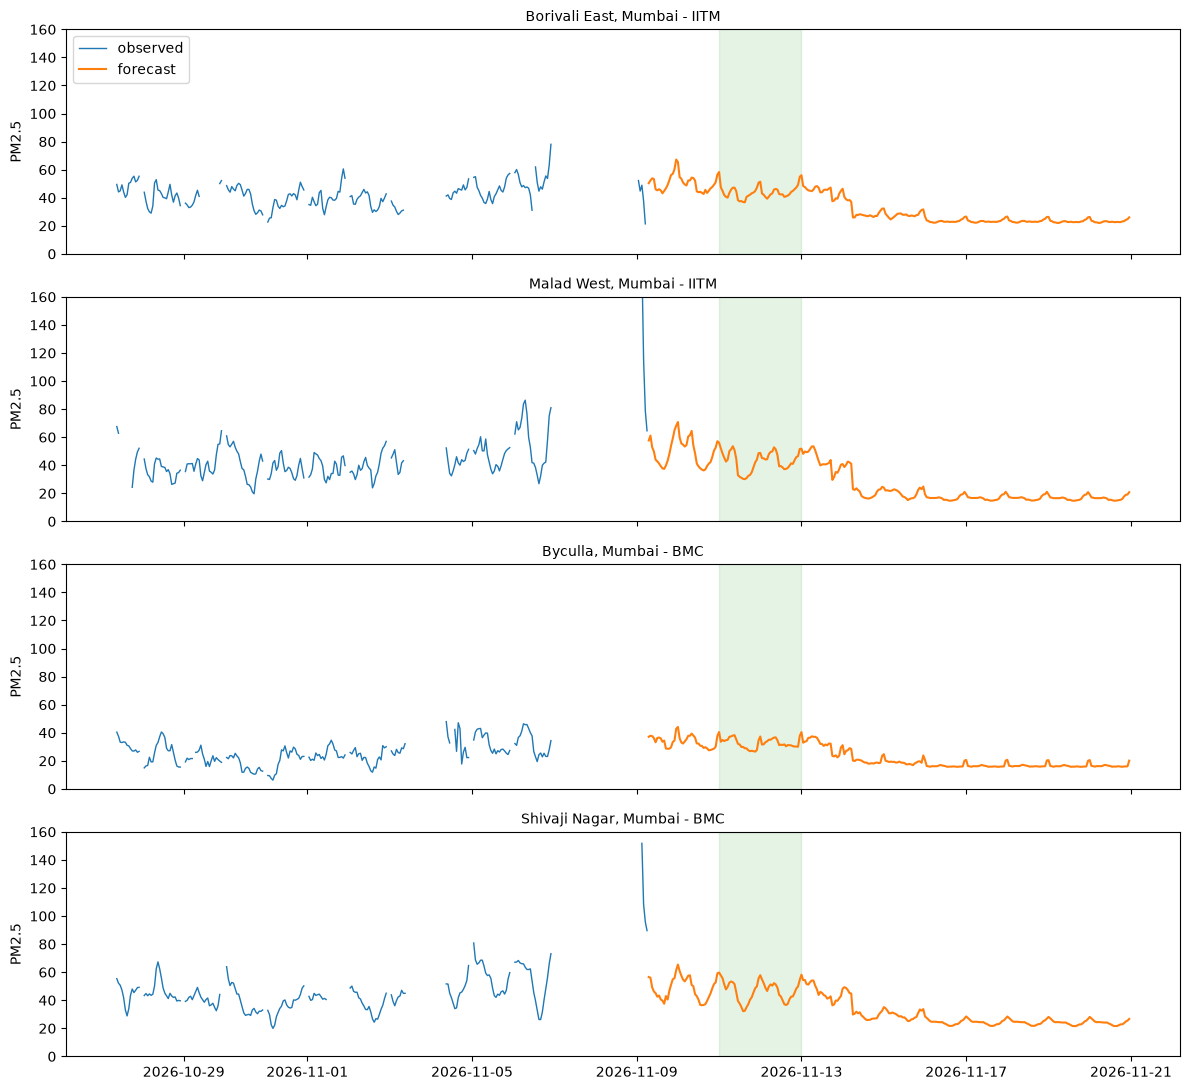

In [8]:
import matplotlib.pyplot as plt
names = pd.read_csv('Stations.csv').set_index('location_id').station_name
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, l in zip(axes, sorted(P_true.columns)):
    o = P_true.loc['2026-10-25':, l]; ax.plot(o.index, o.values, lw=1, label='observed')
    q = te[(te.location_id == l) & (te.t >= C)].sort_values('t'); ax.plot(q.t, q.p, lw=1.5, label='forecast')
    ax.axvspan(pd.Timestamp('2026-11-11'), pd.Timestamp('2026-11-13'), alpha=.12, color='tab:green')
    ax.set_title(names.get(l, l), fontsize=10); ax.set_ylim(0, 160); ax.set_ylabel('PM2.5')
axes[0].legend(loc='upper left'); plt.tight_layout(); plt.show()

## 8. Consistency check against the script output

In [9]:
ref = 'submission.csv' if USE_CAMS else 'submission_nocams.csv'
if os.path.exists(ref):
    r = pd.read_csv(ref); diff = (r.Target - sub.Target).abs()
    m = te.set_index('ID').loc[r.ID, 't'].between('2026-11-11', '2026-11-12 23:00').values
    print(f'vs {ref}: max abs diff all rows = {diff.max():.3f}, private window = {diff[m].max():.3f}')

vs submission.csv: max abs diff all rows = 0.067, private window = 0.000
